In [ ]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


In [2]:
path_data_processed = r"..\1. Données\02_intermediate" + "/welddb_processed.csv"
path_data_correspondance = r"..\1. Données\02_intermediate" + "/correspondance_between_names_units.csv"

df = pd.read_csv(path_data_processed, sep = ";")
correspondance_between_names_units = pd.read_csv(path_data_correspondance, sep = ";")

In [3]:
# détermination des rôles des colonnes
roles = {
    "TARGETS": "Quality indicator",
    "TEST_CONDITION": "Test condition",
    "CHEMISTRY": "Molecular concentration"
}

for variable, role in roles.items():
    globals()[variable] = correspondance_between_names_units.loc[
        correspondance_between_names_units["Role"] == role, "Feature"
    ].tolist()

ID_COL = "Weld ID"


PROCESS_NUM = correspondance_between_names_units.loc[
    (correspondance_between_names_units["Types de variables"] == "float64")
    & (~correspondance_between_names_units["Feature"].isin(TARGETS + [ID_COL] + CHEMISTRY)),
    "Feature"
].tolist()

PROCESS_CAT = correspondance_between_names_units.loc[
    (correspondance_between_names_units["Types de variables"] == "str")
    & (~correspondance_between_names_units["Feature"].isin(TARGETS + [ID_COL] + CHEMISTRY)),
    "Feature"
].tolist()

##  Introduction : prise de connaissance des données

Commençons déjà par prendre connaissance avec les données, qui est une étape essentielle dans des projets data.

In [4]:
# avant de commencer, assurons nous que les lignes entières sont uniques (pas de doublons)
print("Avant suppression des doublons : ", df.shape)
df = df.drop_duplicates()
print("Après suppression des doublons : ", df.shape)
print("Nombre de targets : ", len(TARGETS))
df

Avant suppression des doublons :  (1652, 44)
Après suppression des doublons :  (1651, 44)
Nombre de targets :  7


,Carbon concentration,Silicon concentration,Manganese concentration,Sulphur concentration,Phosphorus concentration,Nickel concentration,Chromium concentration,Molybdenum concentration,Vanadium concentration,Copper concentration,...,Charpy temperature,Charpy impact toughness,Hardness,50 % FATT,Primary ferrite in microstructure,Ferrite with second phase,Acicular ferrite,Martensite,Ferrite with carbide aggreagate,Weld ID
0,0.037,0.30,0.65,0.008,0.012,0.00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990
1,0.037,0.30,0.65,0.008,0.012,0.00,NaN,NaN,NaN,NaN,...,-28.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990
2,0.037,0.30,0.65,0.008,0.012,0.00,NaN,NaN,NaN,NaN,...,-38.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990
3,0.037,0.31,1.03,0.007,0.014,0.00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990
4,0.037,0.31,1.03,0.007,0.014,0.00,NaN,NaN,NaN,NaN,...,-48.0,100.0,NaN,NaN,32.0,28.0,40.0,0.0,0.0,Evans-Ni/CMn-1990
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1647,0.100,0.35,0.90,0.008,0.016,0.60,8.6,0.98,0.18,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Birmingham
1648,0.088,0.36,0.88,0.008,0.017,0.57,8.4,0.94,0.19,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Birmingham
1649,0.090,0.34,0.89,0.008,0.016,0.17,8.2,0.94,0.02,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Birmingham
1650,0.092,0.35,0.90,0.008,0.016,0.54,8.4,0.97,0.17,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Birmingham


En observant notre base de données, on peut connaître les informations suivantes : 
- 44 features différentes, dont 7 features sont les candidats en tant que variables cibles (ce sont des indicateurs de qualité) ; 
- 1651 lignes de données retenues, soit 99% (1651/1652) consérvées après suppression des doublons ; 
- les features `Weld ID` est la seule feature permettant de différencier/séparer les lignes de données. On compte 148 types de soudures différentes.

Ici, une `Weld ID` peut avoir plusieurs lignes, car ce sont les différentes tests effectués sur une soudure. Il indique l'auteur effectuant le test, le sujet d'étude sur la soudure et l'année de publication des résultats (par exemple : **Evans-Ni/CMn-1990** avec Evans l'auteur, l'étude est sur la réaction du Nickel et les résultats sont publiés en 1990). 

Naturellement, on déduit que l'état des données sera dépendante du `Weld ID` car ils ont été tous extraites des expériences et chacun des auteurs sont libres de ne partager des données ou non.

In [5]:
df["Weld ID"].value_counts()

Weld ID
Evans-AlTi-1994            114
Evans-StressRelief-1991    110
SvenGret-1990               96
Pat-1981                    79
EvansLetter                 78
                          ... 
EvansLetterC+1Cuch1          1
EvansLetterC+1Cuch2          1
EvansLetterC+1.5Cu           1
EvansLetterC+1.5Cuch1        1
EvansLetterC+1.5Cuch2        1
Name: count, Length: 148, dtype: int64

In [6]:
# Catégorielles
df["Type of weld"] = df["Type of weld"].replace({"ShMA": "MMA"})

## 1. Etudes des valeurs manquantes

Pour que ça soit plus claire, nous allons regarder la répartition de valeurs manquantes en fonction des lignes, triés par `Weld ID`, pour chaque feature. Par ailleurs, nous mettrons une couleur vif pour les features à plus de 80% d'instances manquantes.

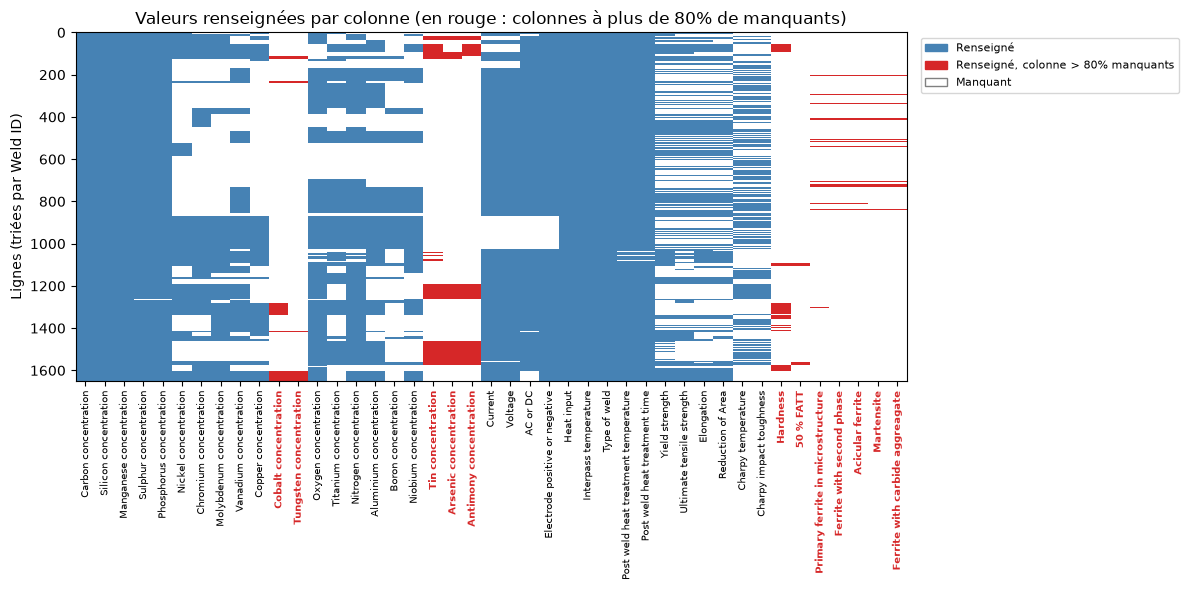

Le nombre de features à plus de 80% de données manquantes est :  12

 Informations sur ces features :


,Feature,Unit,Role,Types de variables
10,Cobalt concentration,(weight%),Molecular concentration,float64
11,Tungsten concentration,(weight%),Molecular concentration,float64
18,Tin concentration,weight %,Molecular concentration,float64
19,Arsenic concentration,weight %,Molecular concentration,float64
20,Antimony concentration,weight %,Molecular concentration,float64
36,Hardness,kg/mm2,Quality indicator,float64
37,50 % FATT,NaN,Quality indicator,float64
38,Primary ferrite in microstructure,%,Microstructure,float64
39,Ferrite with second phase,%,Microstructure,float64
40,Acicular ferrite,%,Microstructure,float64


In [7]:
seuil = 0.80
df_sorted = df.sort_values("Weld ID")
X = df_sorted.drop(columns="Weld ID")
na = X.isna()
taux_na = na.mean()
tres_manquantes = taux_na > seuil

# 0 = manquant, 1 = présent, 2 = présent dans une colonne > 80 % de manquants
code = (~na).astype(int).values
code[:, tres_manquantes.values] *= 2
cmap = ListedColormap(["white", "steelblue", "tab:red"])

plt.figure(figsize=(12, 6))
plt.imshow(code, aspect="auto", interpolation="nearest", cmap=cmap, vmin=0, vmax=2)
plt.xticks(range(X.shape[1]), X.columns, rotation=90, fontsize=7)
for lbl, flag in zip(plt.gca().get_xticklabels(), tres_manquantes):
    if flag:
        lbl.set_color("tab:red"); lbl.set_fontweight("bold")
plt.ylabel("Lignes (triées par Weld ID)")
plt.title(f"Valeurs renseignées par colonne (en rouge : colonnes à plus de {seuil:.0%} de manquants)")
plt.legend(handles=[Patch(color="steelblue", label="Renseigné"),
                    Patch(color="tab:red", label=f"Renseigné, colonne > {seuil:.0%} manquants"),
                    Patch(facecolor="white", edgecolor="gray", label="Manquant")],
           loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout(); plt.show()

print("Le nombre de features à plus de 80% de données manquantes est : ", tres_manquantes.sum())

print("\n Informations sur ces features :")
correspondance_between_names_units[correspondance_between_names_units["Feature"].isin(tres_manquantes[tres_manquantes].index)]

### 1.1) Suppression des features à plus de 80% de valeurs manquantes

Par la précédente analyse, nous avons au total 12 features à plus de 80% de données manquantes. On supprimera : 
- les features de type *microstructure*, car ce sont des résultats du procédé : on ne les connaît pas avant de souder, donc elles ne peuvent pas servir à prédire la qualité ;
- les features de type *qualité de soudure*, car les données sont trop rares ;
- les features de type *concentration moléculaire*, car les données sont trop peu pour avoir une imputation correcte.

In [8]:
df = df.drop(tres_manquantes[tres_manquantes].index, axis=1, inplace=False)

### 1.2) Etude des autres features



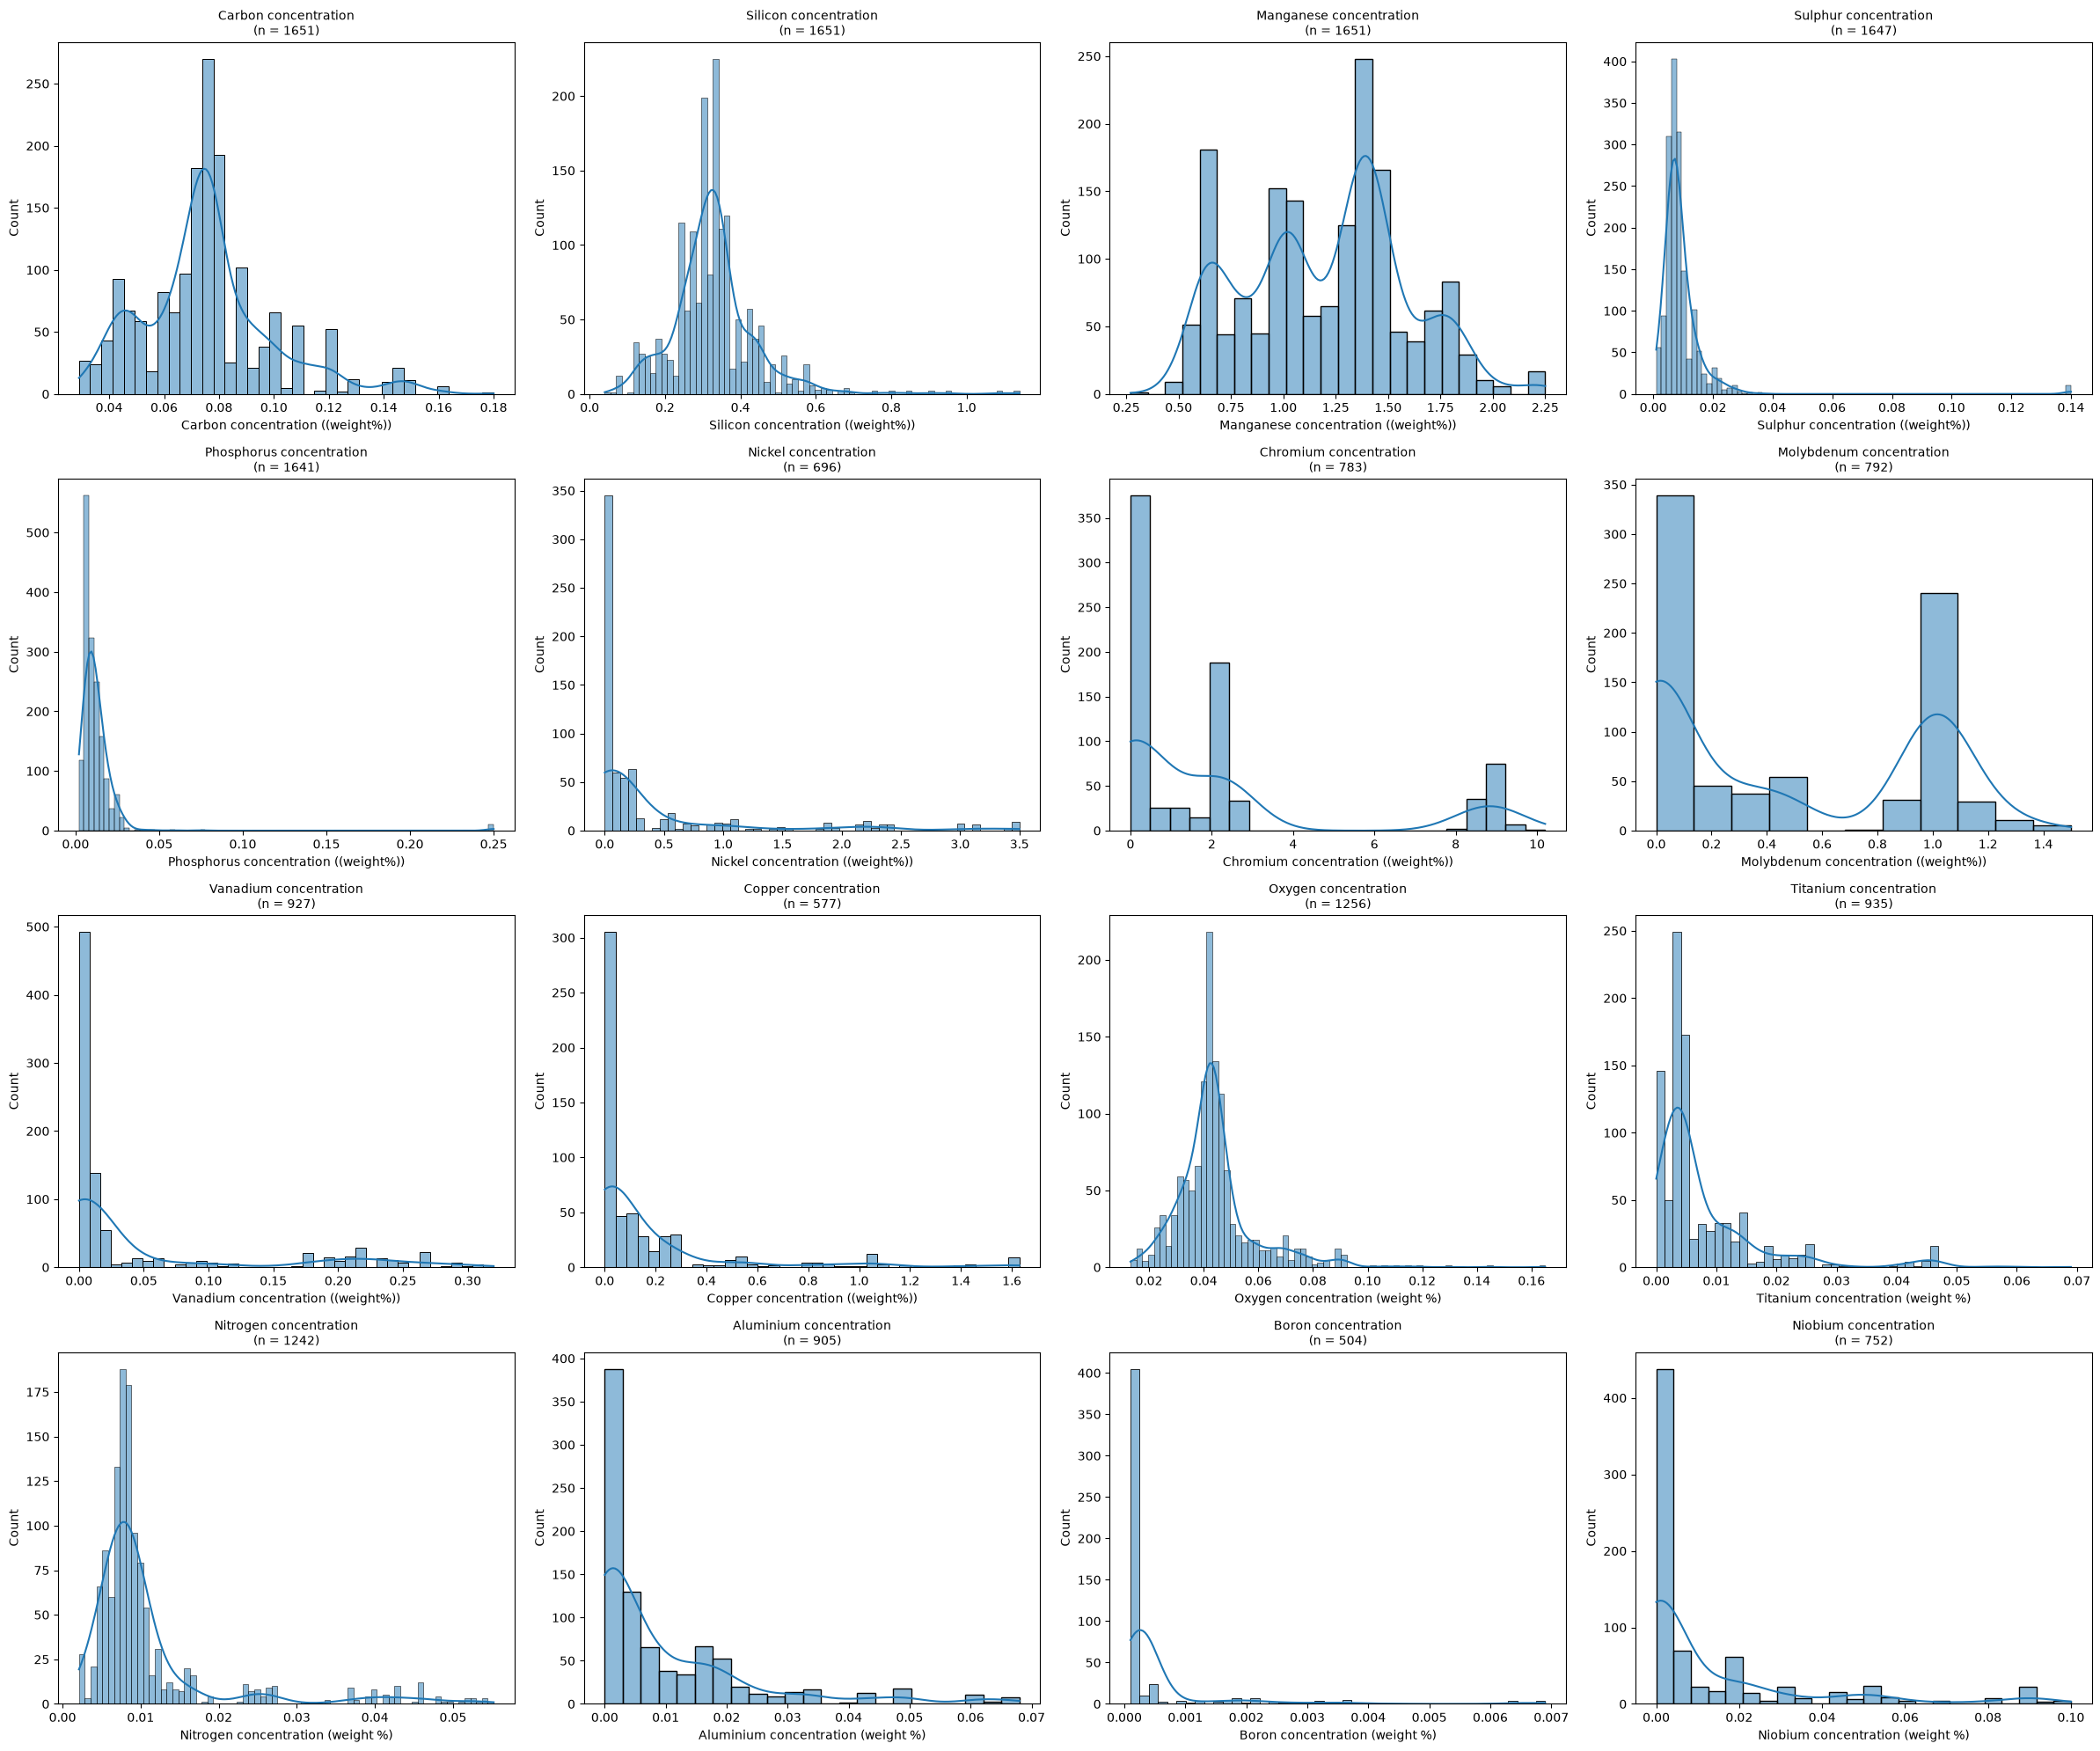

In [ ]:
CHEMISTRY = [t for t in CHEMISTRY if t in df.columns]

ncols = 4  # nb de graphiques par ligne
nrows = -(-len(CHEMISTRY) // ncols)  # division arrondie vers le haut

fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows), squeeze=FalseCHEMISTRY = [t for t in CHEMISTRY if t in df.columns]

ncols = 4  # nb de graphiques par ligne
nrows = -(-len(CHEMISTRY) // ncols)  # division arrondie vers le haut

fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False)

for ax, t in zip(axes.flat, CHEMISTRY):
    sns.histplot(df[t].dropna(), ax=ax, kde=True)
    ax.set_title(f"{t}\n(n = {df[t].notna().sum()})", fontsize=10)
    unit = correspondance_between_names_units.loc[
        correspondance_between_names_units['Feature'] == t, 'Unit'
    ].values[0]
    ax.set_xlabel(t if pd.isna(unit) else f"{t} ({unit})")

# masquer les cases vides
for ax in axes.flat[len(CHEMISTRY):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show())

for ax, t in zip(axes.flat, CHEMISTRY):
    sns.histplot(df[t].dropna(), ax=ax, kde=True)
    ax.set_title(f"{t}\n(n = {df[t].notna().sum()})", fontsize=10)
    unit = correspondance_between_names_units.loc[
        correspondance_between_names_units['Feature'] == t, 'Unit'
    ].values[0]
    ax.set_xlabel(t if pd.isna(unit) else f"{t} ({unit})")

# masquer les cases vides
for ax in axes.flat[len(CHEMISTRY):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

Nous remarquons quelques éléments intéressants pour les concentration moléculaires ou chimiques. Certaines d'entre-elles ont un très grand nombre de 0.Même si l'énoncé explique qu'il y a des valeurs non rapporté, mais cela n'empêche pas de remplir "0" ou ne le mentionne pas quand l'auteur n'ajoute pas l'élément. On repère notamment ces éléments : le nickel, le chromium, le molybdenium, le vanadium, le copper, le titanium, l'aluminium, le niobium et le boron.

Les autres concentrations en manquent pas beaucoup, moins de 30% et ont une répartition bien étendu. Nous allons donc les imputer par la médiane pour ces features : le sulphur, le phorphorus, l'oxygène et le nitrogène. Juste pour les deux derniers, leur teneur dépend surtout du procédé : protection par laitier, flux ou gaz. Ainsi la médiane sera calculée par type de soudage (MMA, SA, FCA…) est donc la meilleure estimation simple.

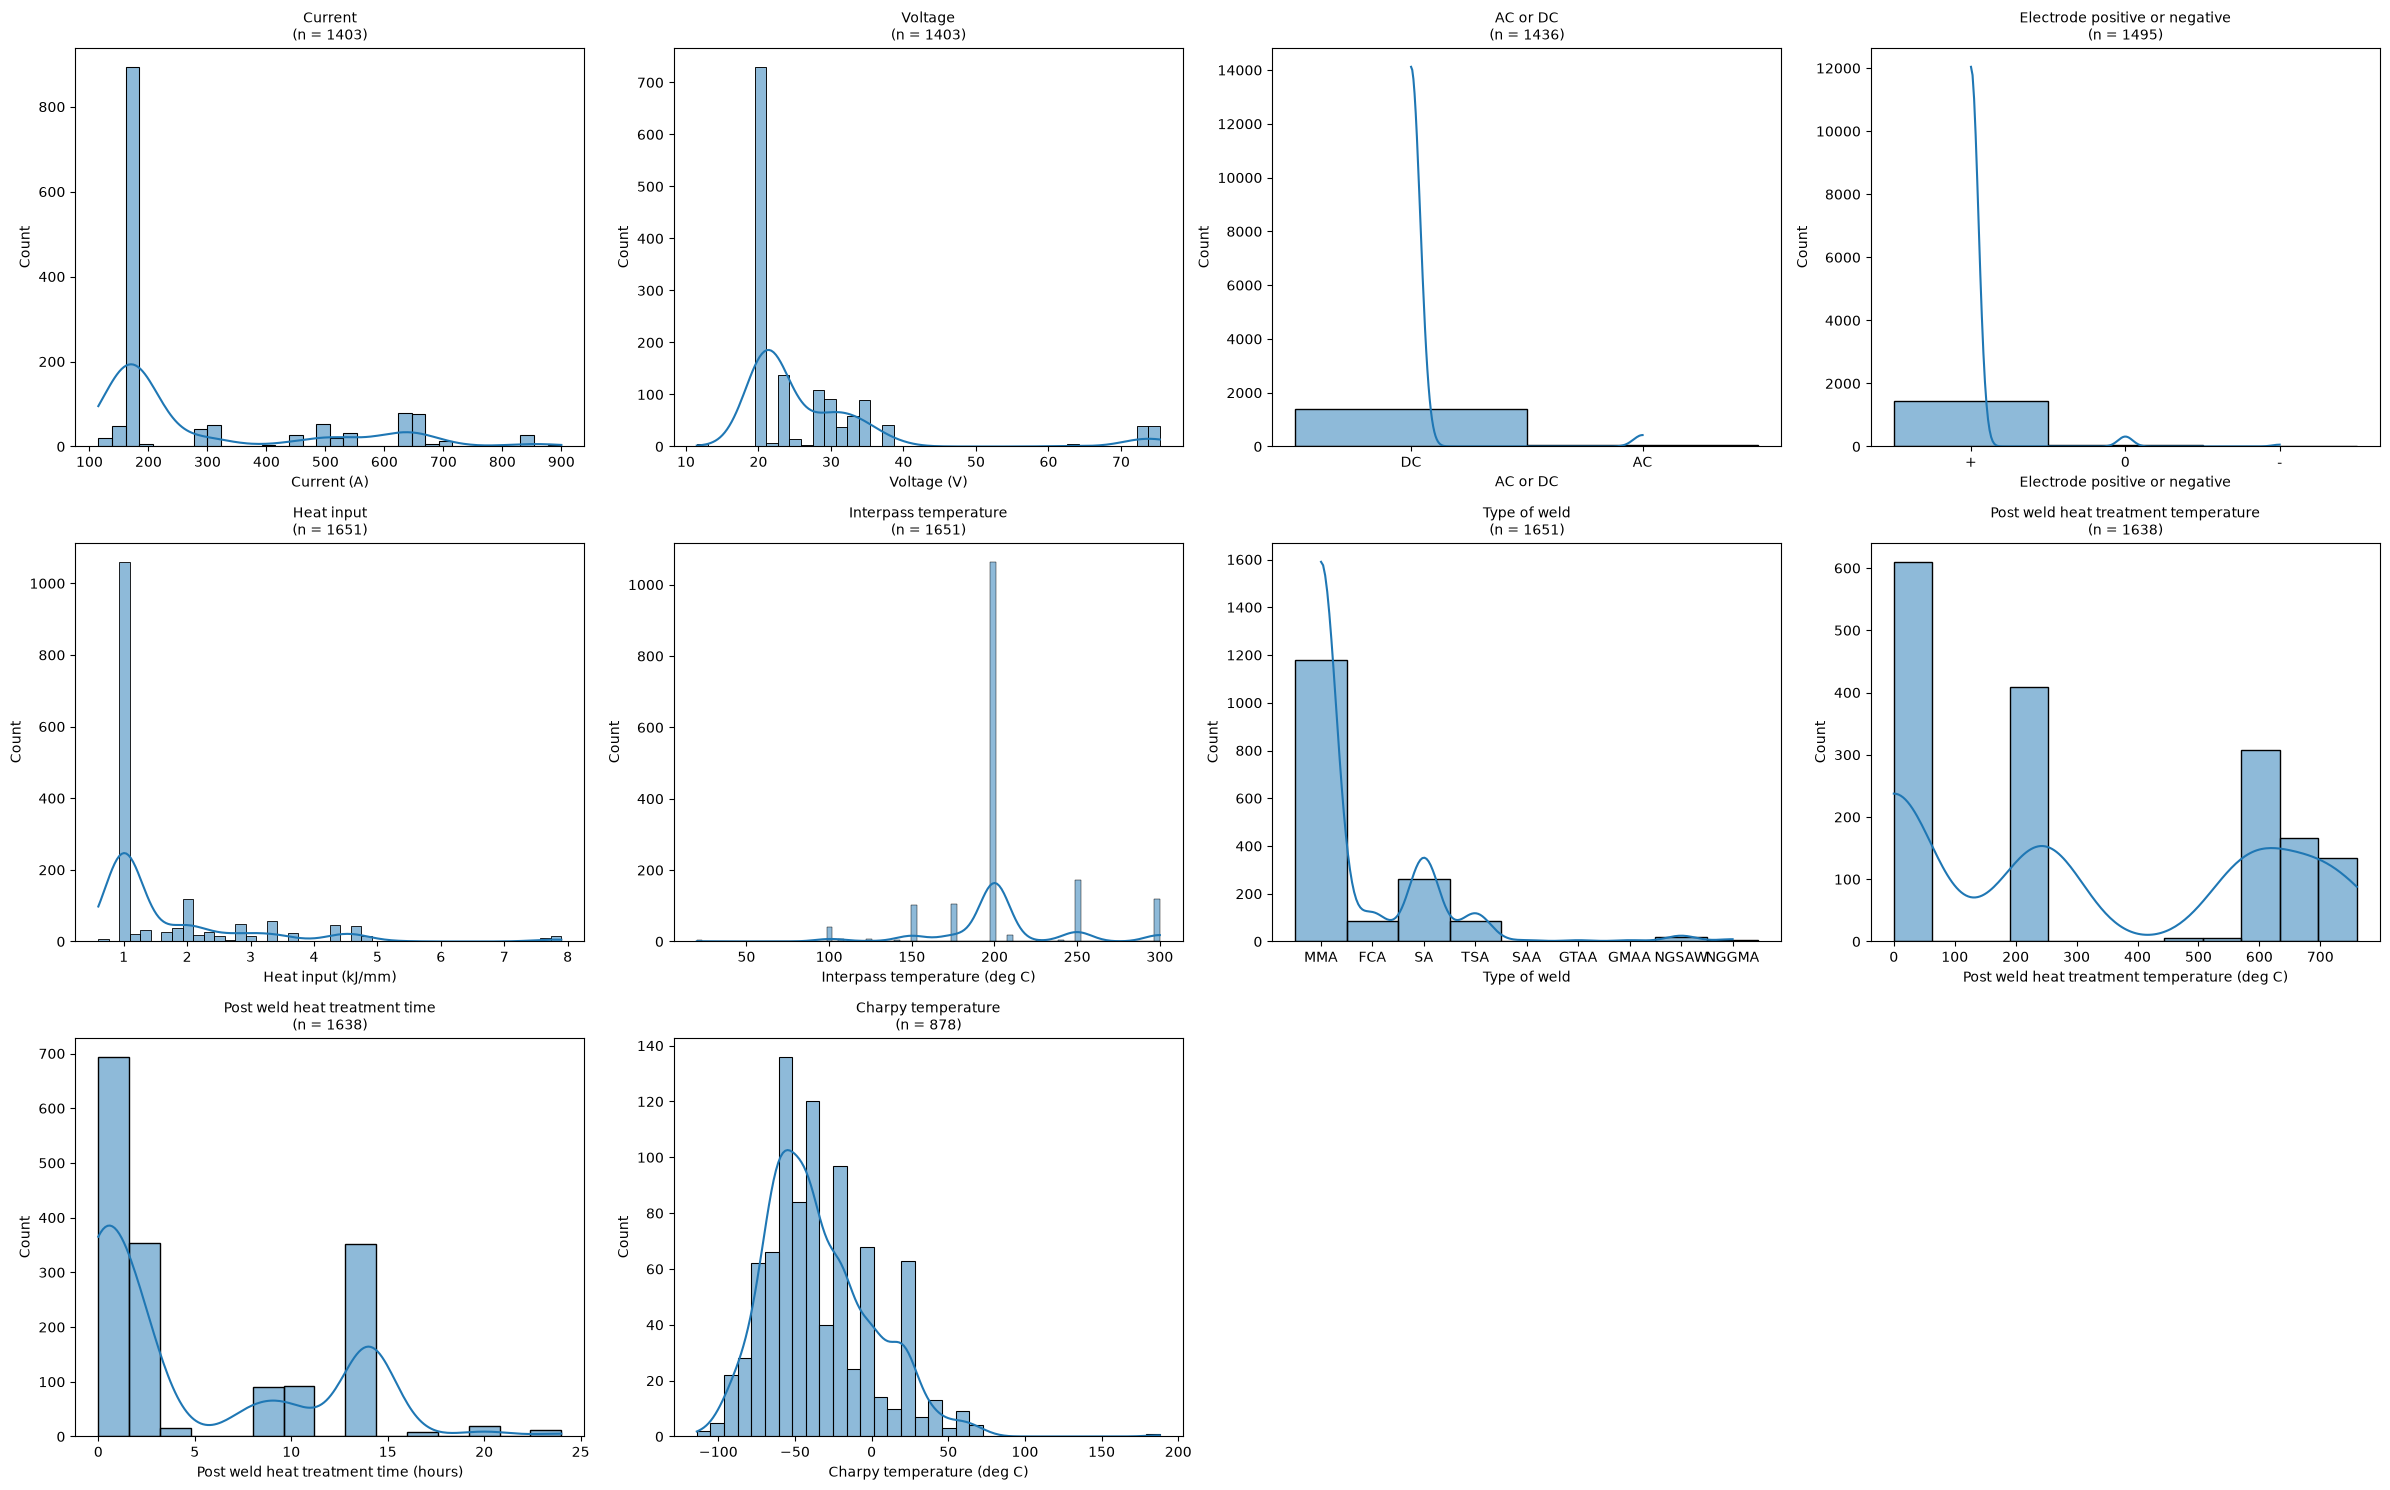

In [32]:
LIST = [col for col in df.columns.tolist() if col not in TARGETS + [ID_COL] + CHEMISTRY]

ncols = 4  # nb de graphiques par ligne
nrows = -(-len(LIST) // ncols)  # division arrondie vers le haut

fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False)

for ax, t in zip(axes.flat, LIST):
    sns.histplot(df[t].dropna(), ax=ax, kde=True)
    ax.set_title(f"{t}\n(n = {df[t].notna().sum()})", fontsize=10)
    unit = correspondance_between_names_units.loc[
        correspondance_between_names_units['Feature'] == t, 'Unit'
    ].values[0]
    ax.set_xlabel(t if pd.isna(unit) else f"{t} ({unit})")

# masquer les cases vides
for ax in axes.flat[len(LIST):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

Ici pour le courrant et la tension, on l'imputera par la médiane. 

Pour les colonnes `AC/DC` et `Electrode positive or negative`, nous pourrons les combiner en une seule variable (par exemple : DC-, DC+ ou AC). Pour le traitement thermique, nous pouvons directeemnt supprimer les 13 lignes vides, car ils proviennent du même article.

Nous allons juste traiter le changement de `Type of weld` et la suppression des lignes inutiles pour le PWHTT. Le reste qui concerne l'imputation est écrit dans une *class* dans le fichier `utils.py`, et utilisé à la suite. Ces derniers apprennent des éléments sur les données, donc sera lancer après le split des données, et une fois par target disponible.

In [ ]:
df["Type of weld"] = df["Type of weld"].replace({"ShMA": "MMA"})
df = df[df["Post weld heat treatment temperature"].notna()]          # retire les 13 lignes Gar&K

## 2. Etude des outliers de features

Méthode de Tukey (1977) vue en CM0 : une valeur est atypique si elle est hors de $[Q_1 - 1.5\,IQR \; ; \; Q_3 + 1.5\,IQR]$.

Le cours distingue deux cas : **erreur de mesure** (→ traiter comme une valeur manquante) ou **situation extraordinaire** (→ garder). Ici, beaucoup de « outliers » statistiques sont des **aciers volontairement alliés** (ex. soudures 9Cr-1Mo avec ~9 % de chrome) ou des traitements thermiques particuliers : ce sont des cas réels, pas des erreurs. On **détecte sans supprimer**, et on vérifie seulement les valeurs physiquement impossibles.

In [39]:
FEATURES_NUM = [f for f in PROCESS_NUM + CHEMISTRY if f in df.columns.tolist()]
TARGETS = [f for f in TARGETS if f in df.columns.tolist()]

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out = pd.DataFrame({
    "nb outliers IQR": df[FEATURES_NUM + TARGETS].apply(iqr_outliers),
    "min": df[FEATURES_NUM + TARGETS].min(),
    "médiane": df[FEATURES_NUM + TARGETS].median(),
    "max": df[FEATURES_NUM + TARGETS].max(),
    "unité": correspondance_between_names_units.loc[correspondance_between_names_units['Feature'].isin(FEATURES_NUM + TARGETS), 'Unit' ].to_list(),
}).sort_values("nb outliers IQR", ascending=False)
out

,nb outliers IQR,min,médiane,max,unité
Interpass temperature,574,2.000000e+01,200.00000,300.0000,(weight%)
Current,296,1.150000e+02,170.00000,900.0000,(weight%)
Vanadium concentration,187,0.000000e+00,0.00500,0.3200,weight %
Nitrogen concentration,172,2.100000e-03,0.00820,0.0552,deg C
Heat input,157,6.000000e-01,1.00000,7.9000,(weight%)
Oxygen concentration,156,1.320000e-02,0.04230,0.1650,V
Silicon concentration,153,4.000000e-02,0.32000,1.1400,(weight%)
Nickel concentration,126,0.000000e+00,0.06800,3.5000,weight %
Sulphur concentration,121,1.000000e-03,0.00700,0.1400,weight %
Chromium concentration,120,0.000000e+00,0.55500,10.2000,weight %


In [40]:
# Contrôles de cohérence physique (valeurs impossibles = erreurs)
checks = {
    "concentration négative": (df[CHEMISTRY] < 0).any(axis=1),
    "UTS < limite d'élasticité": df["Ultimate tensile strength"] < df["Yield strength"],
    "pourcentage > 100": (df[["Elongation", "Reduction of Area"]] > 100).any(axis=1),
}
pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="nb lignes")

concentration négative       0
UTS < limite d'élasticité    0
pourcentage > 100            0
Name: nb lignes, dtype: int64

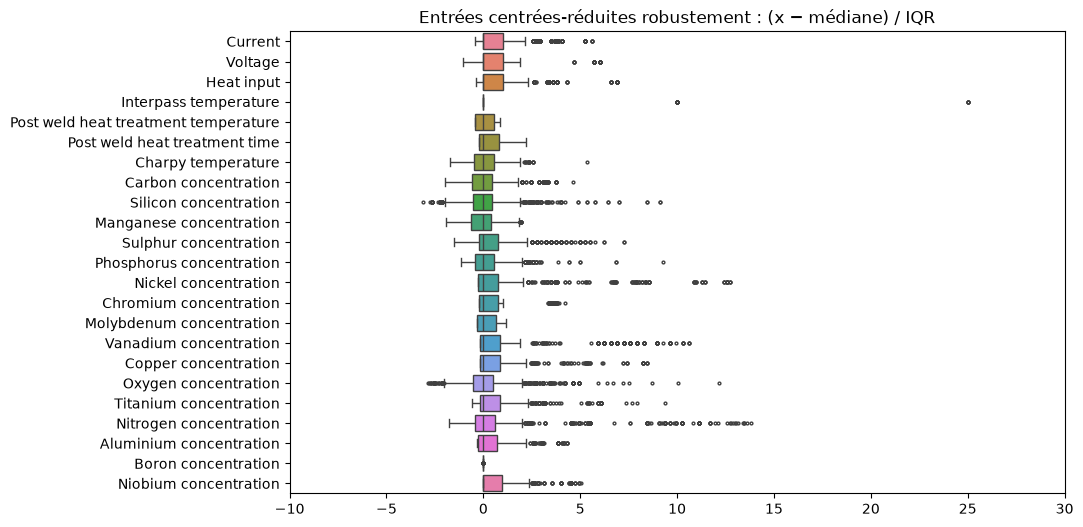

In [41]:
fig, ax = plt.subplots(figsize=(10, 6))
z = (df[FEATURES_NUM] - df[FEATURES_NUM].median()) / (df[FEATURES_NUM].quantile(.75) - df[FEATURES_NUM].quantile(.25)).replace(0, 1)
sns.boxplot(data=z, orient="h", ax=ax, fliersize=2)
ax.set_xlim(-10, 30)
ax.set_title("Entrées centrées-réduites robustement : (x − médiane) / IQR")
plt.show()

## 3. Feature engineering : pour donner plus d'information et avoir une forme adapter pour la prédiction

## 4. Analyse descriptive finale 